# Liquidity Stress Early Warning — mobile money

**Goal:** predict `liquidity_stress_next_30d` — whether a customer hits liquidity stress in the 30 days after an observation date — from six months of mobile money history.

**Output:** `submission.csv` with `ID` and `Target` (probability of stress), matching `SampleSubmission.csv`.

Workflow:
1. Load the data
2. Understand the target and the data's structure
3. Engineer features (trends, flow ratios, balance cover)
4. Validate with 5-fold cross-validation
5. Train on all data and write the submission

Put `Train.csv`, `Test.csv` and `SampleSubmission.csv` in the same folder as this notebook (or change `DATA_DIR`).

In [1]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss
warnings.filterwarnings('ignore')

DATA_DIR = '.'
T = 'liquidity_stress_next_30d'

## Step 1 — Load the data

In [2]:
train = pd.read_csv(f'{DATA_DIR}/Train.csv')
test = pd.read_csv(f'{DATA_DIR}/Test.csv')
sample = pd.read_csv(f'{DATA_DIR}/SampleSubmission.csv')
print('Train:', train.shape, ' Test:', test.shape, ' Sample:', sample.shape)
sample.head()

Train: (40000, 184)  Test: (30000, 183)  Sample: (30000, 2)


,ID,Target
0,ID_ED91AC7A28,0.5
1,ID_29975A9C7E,0.5
2,ID_F59CE25650,0.5
3,ID_E875F68D1A,0.5
4,ID_2902B1C0D0,0.5


## Step 2 — Understand the data

### The target

In [3]:
print(train[T].value_counts(normalize=True))

liquidity_stress_next_30d
0    0.85
1    0.15
Name: proportion, dtype: float64


About **15%** of snapshots end in stress, so the classes are imbalanced. We'll judge models by **AUC** (ranking quality) and **log-loss** (probability quality), not accuracy.

### Column families

Apart from the 7 profile columns, almost every column is one of 29 behaviours measured for each of 6 months: `m1_…` is the most recent month, `m6_…` the oldest.

In [4]:
fams = sorted(set(re.sub(r'^m\d_', '', c) for c in train.columns if re.match(r'^m\d_', c)))
print(len(fams), 'monthly families:'); print(fams)

29 monthly families:
['daily_avg_bal', 'deposit_agents', 'deposit_highest_amount', 'deposit_total_value', 'deposit_volume', 'merchantpay_highest_amount', 'merchantpay_merchants', 'merchantpay_total_value', 'merchantpay_volume', 'mm_send_highest_amount', 'mm_send_recipients', 'mm_send_total_value', 'mm_send_volume', 'paybill_companies', 'paybill_highest_amount', 'paybill_total_value', 'paybill_volume', 'received_highest_amount', 'received_senders', 'received_total_value', 'received_volume', 'transfer_from_bank_banks', 'transfer_from_bank_highest_amount', 'transfer_from_bank_total_value', 'transfer_from_bank_volume', 'withdraw_agents', 'withdraw_highest_amount', 'withdraw_total_value', 'withdraw_volume']


### Customers appear several times

There is no customer ID, but the profile columns (`arpu`, `age`, `gender`, `region`, `smartphone`, `segment`, `earning_pattern`) together identify one customer.

In [5]:
PROFILE = ['arpu', 'age', 'gender', 'region', 'smartphone', 'segment', 'earning_pattern']
ck_tr = train[PROFILE].astype(str).agg('|'.join, axis=1)
ck_te = test[PROFILE].astype(str).agg('|'.join, axis=1)
print('Customers in train:', ck_tr.nunique(), '| in test:', ck_te.nunique(),
      '| in both:', len(set(ck_tr) & set(ck_te)))
print('Snapshots per customer in train:', ck_tr.value_counts().unique(),
      '| in test:', ck_te.value_counts().unique())

Customers in train: 10000 | in test: 10000 | in both: 10000
Snapshots per customer in train: [4] | in test: [3]


10,000 customers, each with **4 snapshots in train and 3 in test**. I tested adding each customer's past stress rate as a feature (computed fold-safely): it did **not** improve the score (AUC 0.9138 → 0.9139). Stress depends on what happens *within* a snapshot, not on who the customer is, so we leave it out.

### A first look at the signal

Compare balance in the last 3 months with months 4–6:

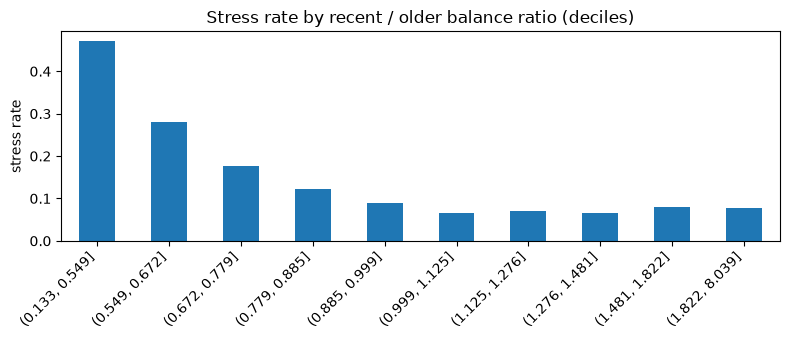

In [6]:
bal = train[[f'm{i}_daily_avg_bal' for i in range(1, 7)]].values
ratio = (bal[:, :3].mean(1) + 1) / (bal[:, 3:].mean(1) + 1)
bins = pd.qcut(ratio, 10)
rate = train.groupby(bins, observed=True)[T].mean()
rate.plot.bar(figsize=(8, 3.5))
plt.title('Stress rate by recent / older balance ratio (deciles)'); plt.ylabel('stress rate'); plt.xlabel('')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

Customers whose balance has **fallen** recently are far more likely to be stressed. That points to **trend features**: comparing recent months against older months.

## Step 3 — Feature engineering

For every monthly family we add:
- **level and spread:** mean, std, coefficient of variation, min, max, number of zero months
- **trend:** latest month vs average, last 3 vs months 4–6, linear slope

Then cash-flow features over the last 1, 2, 3, 4 and 6 months:
- **inflow** = received + deposits + bank transfers in; **outflow** = withdrawals + sends + paybill + merchant payments
- net flow, outflow/inflow ratio, cash-out share of outflow, balance cover (balance ÷ outflow, balance ÷ ARPU)

Plus finer recency ratios (last k months vs the rest, k = 1, 2, 4, 5) for the key families, and two interaction features combining outflow pressure with the balance trend.

Train and test are processed together. This uses **no labels**, so it doesn't leak.

In [7]:
CATS = ['gender', 'region', 'smartphone', 'segment', 'earning_pattern']
al = pd.concat([train.assign(is_tr=1), test.assign(is_tr=0)], ignore_index=True)

def months(f, k=6):
    return al[[f'm{i}_{f}' for i in range(1, k + 1)]]

# --- per-family summaries and trends
new = {}
for f in fams:
    M = months(f).values.astype(float)
    mean = M.mean(1)
    new[f'{f}_mean'] = mean
    new[f'{f}_std'] = M.std(1)
    new[f'{f}_cv'] = M.std(1) / (mean + 1)
    new[f'{f}_min'] = M.min(1)
    new[f'{f}_max'] = M.max(1)
    new[f'{f}_zeros'] = (M == 0).sum(1)
    new[f'{f}_m1_rel'] = M[:, 0] / (mean + 1)
    new[f'{f}_recent_vs_old'] = (M[:, :3].mean(1) + 1) / (M[:, 3:].mean(1) + 1)
    # slope over time (oldest -> newest), scaled by the mean
    new[f'{f}_slope'] = np.polyfit(np.arange(6), M.T[::-1], 1)[0] / (mean + 1)
F = pd.DataFrame(new)

# --- cash-flow features over several windows
IN = ['received_total_value', 'deposit_total_value', 'transfer_from_bank_total_value']
OUT = ['withdraw_total_value', 'mm_send_total_value', 'paybill_total_value', 'merchantpay_total_value']
def window_sum(f, k):
    return months(f, k).sum(1)

for k in (1, 2, 3, 4, 6):
    inflow = sum(window_sum(f, k) for f in IN)
    outflow = sum(window_sum(f, k) for f in OUT)
    F[f'out_in_ratio_{k}m'] = outflow / (inflow + 1)
    if k in (1, 3, 6):
        F[f'inflow_{k}m'] = inflow
        F[f'outflow_{k}m'] = outflow
        F[f'net_{k}m'] = inflow - outflow
        F[f'cashout_share_{k}m'] = window_sum('withdraw_total_value', k) / (outflow + 1)
        F[f'bal_to_out_{k}m'] = window_sum('daily_avg_bal', k) / (outflow + 1)
        F[f'bal_to_arpu_{k}m'] = window_sum('daily_avg_bal', k) / (al['arpu'] + 1)
F['bal_m1_over_max'] = al['m1_daily_avg_bal'] / (F['daily_avg_bal_max'] + 1)
F['bal_m1_m2'] = (al['m1_daily_avg_bal'] + 1) / (al['m2_daily_avg_bal'] + 1)

# --- finer recency windows for the key families
KEYF = ['daily_avg_bal', 'withdraw_total_value', 'deposit_total_value', 'received_total_value',
        'paybill_total_value', 'merchantpay_total_value', 'mm_send_total_value',
        'transfer_from_bank_total_value', 'withdraw_highest_amount', 'withdraw_volume']
for f in KEYF:
    M = months(f).values.astype(float)
    for k in (1, 2, 4, 5):
        F[f'{f}_r{k}'] = (M[:, :k].mean(1) + 1) / (M[:, k:].mean(1) + 1)
    F[f'{f}_log_r3'] = np.log1p(M[:, :3].mean(1)) - np.log1p(M[:, 3:].mean(1))

# --- interactions: outflow pressure x balance trend
F['oi3_x_bal'] = F['out_in_ratio_3m'] * np.log1p(F['daily_avg_bal_mean'])
F['oi3_div_balr'] = F['out_in_ratio_3m'] / (F['daily_avg_bal_recent_vs_old'] + 0.01)

al = pd.concat([al, F], axis=1)
for c in CATS:
    al[c] = al[c].astype('category')

trn = al[al.is_tr == 1].reset_index(drop=True)
tst = al[al.is_tr == 0].reset_index(drop=True)
y = trn[T].values.astype(int)
FEATURES = [c for c in al.columns if c not in ('ID', T, 'is_tr')]
print('Number of features:', len(FEATURES))

Number of features: 520


## Step 4 — Validate with cross-validation

**LightGBM** (gradient-boosted trees) handles mixed scales, categories and non-linear ratios well with no scaling. We split train into 5 stratified folds, train on 4, score the 5th, and rotate. **Early stopping** picks the number of trees for each fold.

A random row split mirrors the test set, where every customer has also been seen in train.

In [8]:
PARAMS = dict(n_estimators=5000, learning_rate=0.02, num_leaves=31, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=2.0,
              random_state=0, verbose=-1)

oof = np.zeros(len(trn))
best_iters, gain = [], np.zeros(len(FEATURES))
for fold, (a, b) in enumerate(StratifiedKFold(5, shuffle=True, random_state=0).split(trn, y), 1):
    m = lgb.LGBMClassifier(**PARAMS)
    m.fit(trn.loc[a, FEATURES], y[a], eval_set=[(trn.loc[b, FEATURES], y[b])], eval_metric='auc',
          callbacks=[lgb.early_stopping(200, verbose=False)])
    oof[b] = m.predict_proba(trn.loc[b, FEATURES])[:, 1]
    best_iters.append(m.best_iteration_)
    gain += m.booster_.feature_importance('gain') / 5
    print(f'Fold {fold}: AUC = {roc_auc_score(y[b], oof[b]):.4f}  (trees: {m.best_iteration_})')

print(f'\nOverall out-of-fold AUC = {roc_auc_score(y, oof):.4f}   log-loss = {log_loss(y, oof):.4f}')
print(f'Baseline log-loss (always predict 15%) = {log_loss(y, np.full(len(y), y.mean())):.4f}')

Fold 1: AUC = 0.9118  (trees: 310)
Fold 2: AUC = 0.9180  (trees: 462)
Fold 3: AUC = 0.9129  (trees: 545)
Fold 4: AUC = 0.9096  (trees: 479)
Fold 5: AUC = 0.9192  (trees: 450)

Overall out-of-fold AUC = 0.9142   log-loss = 0.2387
Baseline log-loss (always predict 15%) = 0.4227


**How to read this**
- **AUC ≈ 0.91:** pick one stressed and one non-stressed snapshot at random, and the model ranks the stressed one higher about 91% of the time (0.5 = coin flip).
- **Log-loss** falls well below the "always 15%" baseline, so the probabilities carry real information.

## Step 5 — What did the model learn?

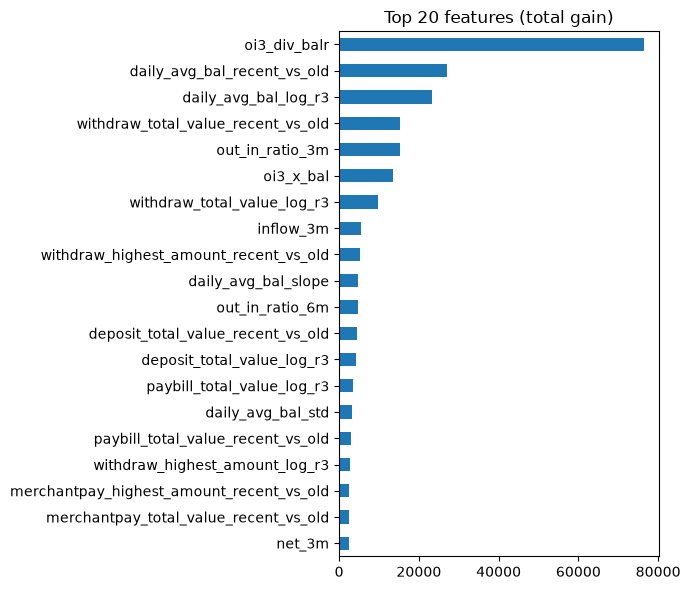

In [9]:
imp = pd.Series(gain, index=FEATURES).sort_values(ascending=False)
imp.head(20)[::-1].plot.barh(figsize=(7, 6))
plt.title('Top 20 features (total gain)'); plt.tight_layout(); plt.show()

The top signals all describe a **squeeze over the last 3 months**:
- outflows catching up with inflows (`out_in_ratio_3m`)
- balance falling compared with months 4–6 (`daily_avg_bal_recent_vs_old`, `daily_avg_bal_log_r3`, `daily_avg_bal_slope`)
- the two combined (`oi3_div_balr`), which is the strongest single feature
- withdrawals rising (`withdraw_total_value_recent_vs_old`)

That matches the intuition: a customer spending faster than money comes in, while their buffer shrinks, is heading for stress.

## Step 6 — Train on all data and write the submission

The final model trains on all 40,000 rows with about 1.1× the average best tree count from CV. We average **3 random seeds** for slightly more stable predictions, then align rows to `SampleSubmission.csv` by `ID`.

In [10]:
n_trees = int(np.mean(best_iters) * 1.1)
pred = np.zeros(len(tst))
for seed in range(3):
    m = lgb.LGBMClassifier(**{**PARAMS, 'n_estimators': n_trees, 'random_state': seed})
    m.fit(trn[FEATURES], y)
    pred += m.predict_proba(tst[FEATURES])[:, 1] / 3

submission = sample[['ID']].merge(pd.DataFrame({'ID': tst['ID'], 'Target': pred}), on='ID', how='left')

# sanity checks: same rows, same order, same columns, no gaps
assert len(submission) == len(sample)
assert list(submission.columns) == list(sample.columns)
assert (submission['ID'] == sample['ID']).all()
assert submission['Target'].between(0, 1).all()

submission.to_csv('submission.csv', index=False)
print(f'Saved submission.csv  ({len(submission)} rows, trees per model: {n_trees})')
print(f'Mean predicted stress: {submission.Target.mean():.3f}  vs train rate {y.mean():.3f}')
submission.head()

Saved submission.csv  (30000 rows, trees per model: 494)
Mean predicted stress: 0.151  vs train rate 0.150


,ID,Target
0,ID_ED91AC7A28,0.014880
1,ID_29975A9C7E,0.059638
2,ID_F59CE25650,0.013267
3,ID_E875F68D1A,0.003915
4,ID_2902B1C0D0,0.005892


## Ideas to improve (try one at a time and check the CV score)

1. **Blend model types:** add CatBoost or XGBoost and average with LightGBM.
2. **Tune LightGBM:** `num_leaves`, `min_child_samples`, `colsample_bytree` with Optuna.
3. **Feature selection:** drop low-gain features; 500+ features add noise.
4. **More flow detail:** per-family recent-vs-old ratios for *volumes* and *counterparties* (agents, recipients, senders).
5. **Check the metric:** if Zindi scores log-loss, keep the probabilities as they are; if AUC, rank-averaging blends is safe too.